# Higgins et al. (ICLR 2017), Figure 7A/B: reproduction

All training, evaluation and plotting code (`phase1.py`) was written by **Claude Sonnet 5.5 (Medium effort) in the claude.ai chat
interface**; the conversation is in `llm_transcript.md`. This notebook only calls that script and shows its outputs.

Setup (paper Table 1): FC encoder 1200-1200, 10 latents, FC decoder 1200-1200-1200-4096 (tanh), Bernoulli likelihood, Adagrad lr 1e-2;
batch 64, 300k steps (our choices); β = 4 (7A) and β = 1 (7B); seeds 0, 1, 2.

Data: `dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz` from https://github.com/google-deepmind/dsprites-dataset, saved as
`../data/dsprites.npz`.

In [1]:
import subprocess, sys
from pathlib import Path
from IPython.display import Image, display

HERE = Path.cwd()                      # run this notebook from its own folder
PY = sys.executable
RUN_TRAINING = False                   # True = retrain from scratch (hours on a laptop GPU)

def run(*args):
    """Run one of the LLM-generated scripts and stream its output."""
    cmd = [PY, *map(str, args)]
    print("$", " ".join(cmd))
    subprocess.run(cmd, cwd=HERE, check=True)

def show_csv(path):
    import csv
    rows = list(csv.reader(open(path)))
    w = [max(len(r[i]) for r in rows) for i in range(len(rows[0]))]
    for r in rows:
        print("  ".join(c.ljust(n) for c, n in zip(r, w)))

## 1. Train (if no checkpoint exists) and draw Figure 7 for every run
With all six checkpoints present (`phase1_runs/beta*_seed*/model.pt`, about 57 MB each) this only re-evaluates and redraws. Otherwise it shows the saved figures, unless `RUN_TRAINING = True`, which trains any missing run (about 0.5–1.5 h each on an Apple-silicon GPU).

In [2]:
ckpts = list((HERE / "phase1_runs").glob("beta*_seed*/model.pt"))
if RUN_TRAINING or len(ckpts) == 6:     # all 6 runs present: re-evaluate and redraw only, no training
    run("phase1.py", "--data", "../data/dsprites.npz", "--out", "phase1_runs", "--seed_start", "0", "--num_seeds", "3")
else:
    print(f"{len(ckpts)}/6 checkpoints and RUN_TRAINING=False: showing the saved figures.")

$ /Volumes/Projects/CS_6362-Advanced_Machine_Learning/assignment2/.venv/bin/python phase1.py --data ../data/dsprites.npz --out phase1_runs --seed_start 0 --num_seeds 3


device: mps
traversal seed image index: 305711
loaded phase1_runs/beta4_seed0/model.pt

== beta=4 seed=0 ==
recon NLL (sampled z): 65.50 nats/image (0.01599/pixel); mean-z: 56.21
KL total: 11.58; active latents (KL>0.1): 5
per-latent KL, ordered by posterior variance ascending:
  z8:3.319  z2:2.609  z9:2.356  z4:2.130  z7:1.166  z3:0.000  z1:0.000  z6:0.000  z0:0.000  z5:0.000
loaded phase1_runs/beta4_seed1/model.pt

== beta=4 seed=1 ==
recon NLL (sampled z): 61.40 nats/image (0.01499/pixel); mean-z: 51.92
KL total: 12.03; active latents (KL>0.1): 5
per-latent KL, ordered by posterior variance ascending:
  z5:3.178  z3:2.733  z9:2.531  z0:1.816  z1:1.771  z2:0.001  z6:0.000  z4:0.000  z8:0.000  z7:0.000
loaded phase1_runs/beta4_seed2/model.pt

== beta=4 seed=2 ==
recon NLL (sampled z): 70.69 nats/image (0.01726/pixel); mean-z: 61.52
KL total: 11.16; active latents (KL>0.1): 5
per-latent KL, ordered by posterior variance ascending:
  z7:3.266  z2:2.914  z8:2.531  z6:1.484  z5:0.964  z1:

## 2. Summary over seeds

In [3]:
show_csv("phase1_runs/summary_all_runs.csv")

beta  seed  recon_nll_sampled_z  recon_nll_mean_z    kl_total            n_active_latents  train_seconds       kl_z0                   kl_z1                   kl_z2                  kl_z3                   kl_z4                   kl_z5                   kl_z6                  kl_z7                  kl_z8                  kl_z9                 
4.0   0     65.49942016601562    56.21379089355469   11.580546379089355  5                 3645.2181689739227  0.0003081497270613909   0.00021714848116971552  2.6085221767425537     0.0003524524800013751   2.1301677227020264      0.00019429431995376945  0.0002739756600931287  1.1655855178833008     3.3194122314453125     2.3555126190185547    
4.0   1     61.401100158691406   51.923519134521484  12.030221939086914  5                 1632.5246920585632  1.8155059814453125      1.7713236808776855      0.0006583846407011151  2.732638120651245       0.00030240826890803874  3.177511692047119       0.0004617489757947624  0.0002467363083269447  0.000263

## 3. Original Figure 7A/B

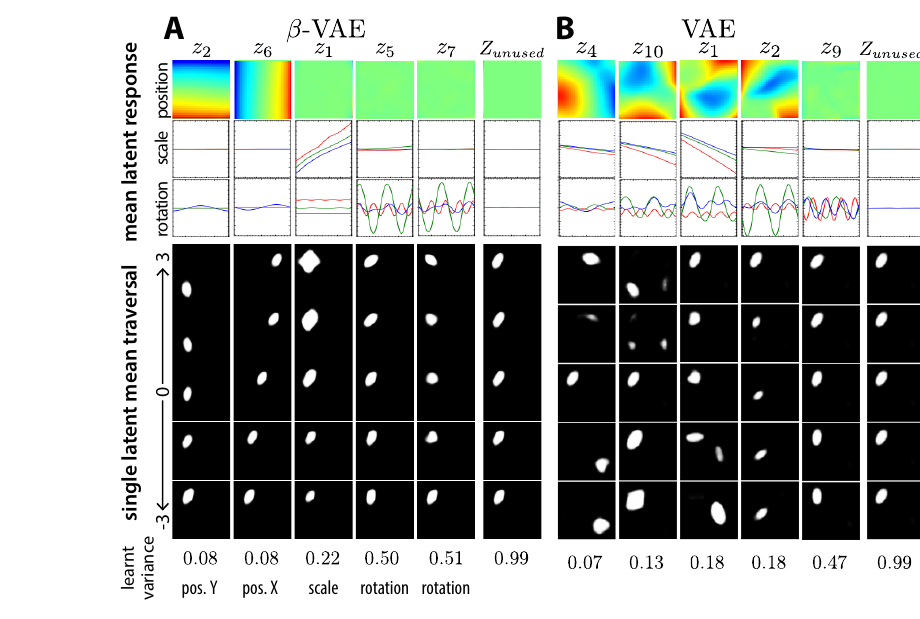

In [4]:
display(Image("original_figure7AB.png"))

## 4. Reproduction: β = 4 (Fig. 7A) and β = 1 (Fig. 7B), every seed

beta4_seed0


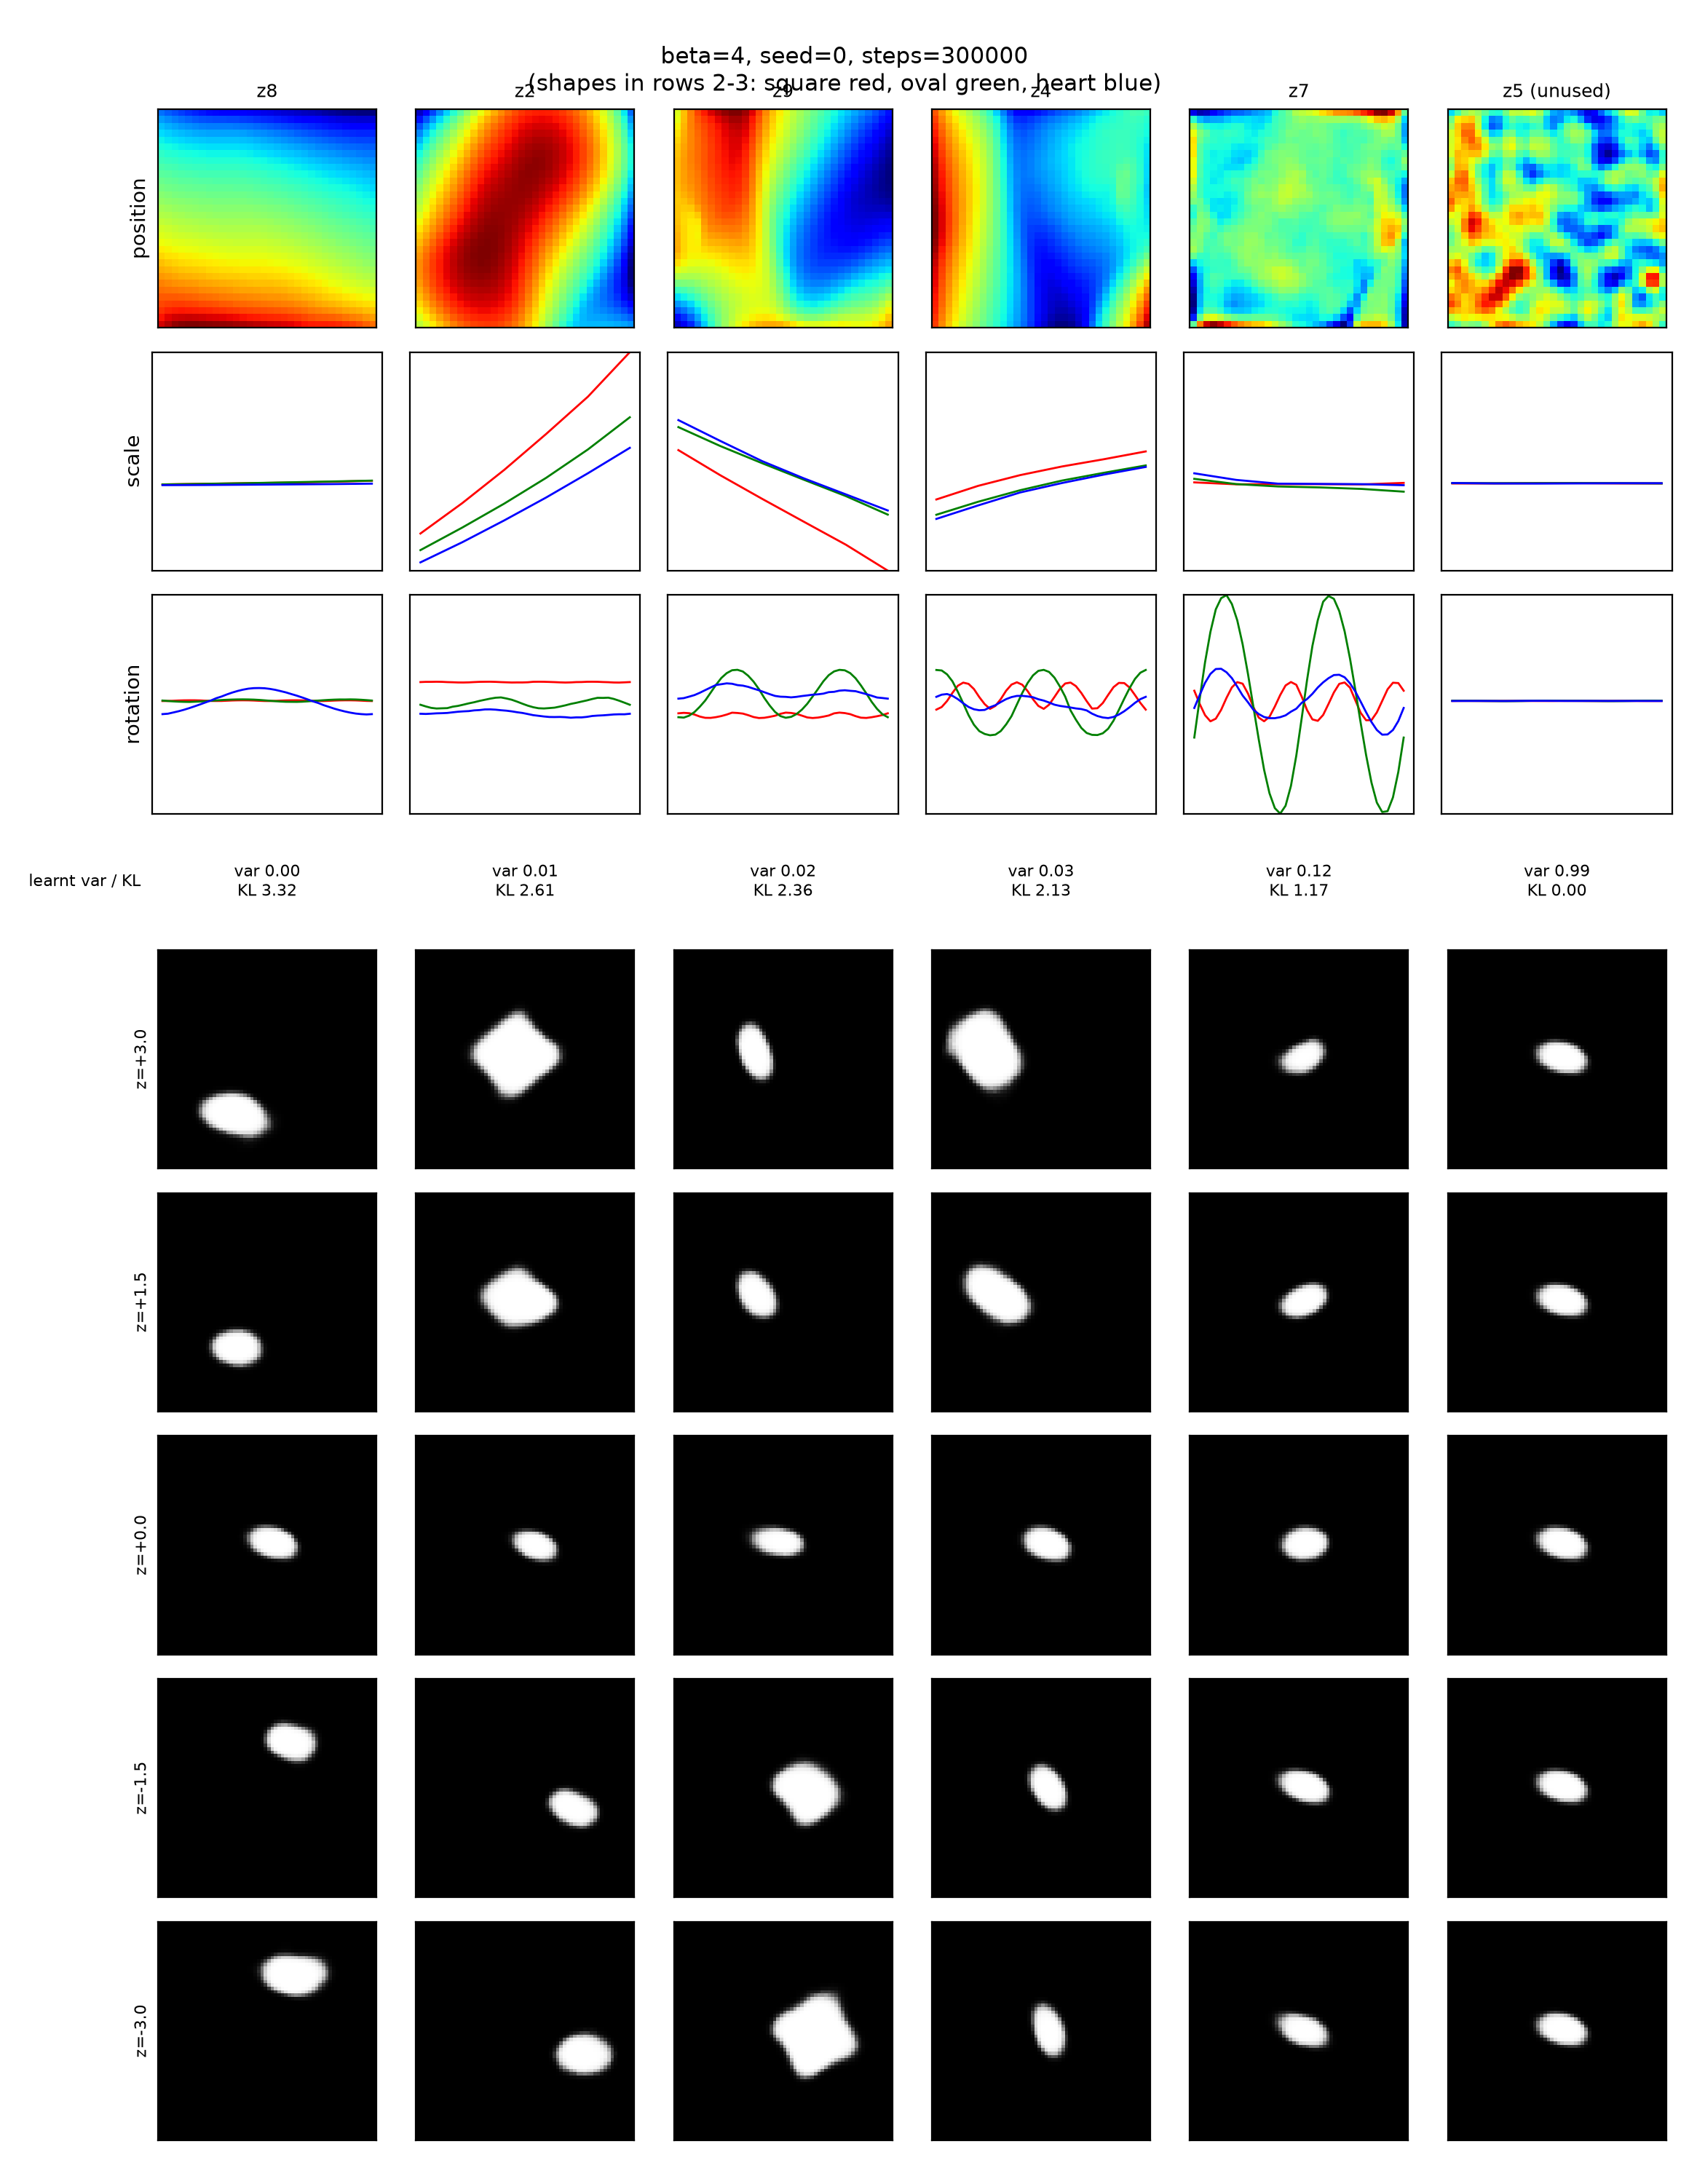

beta4_seed1


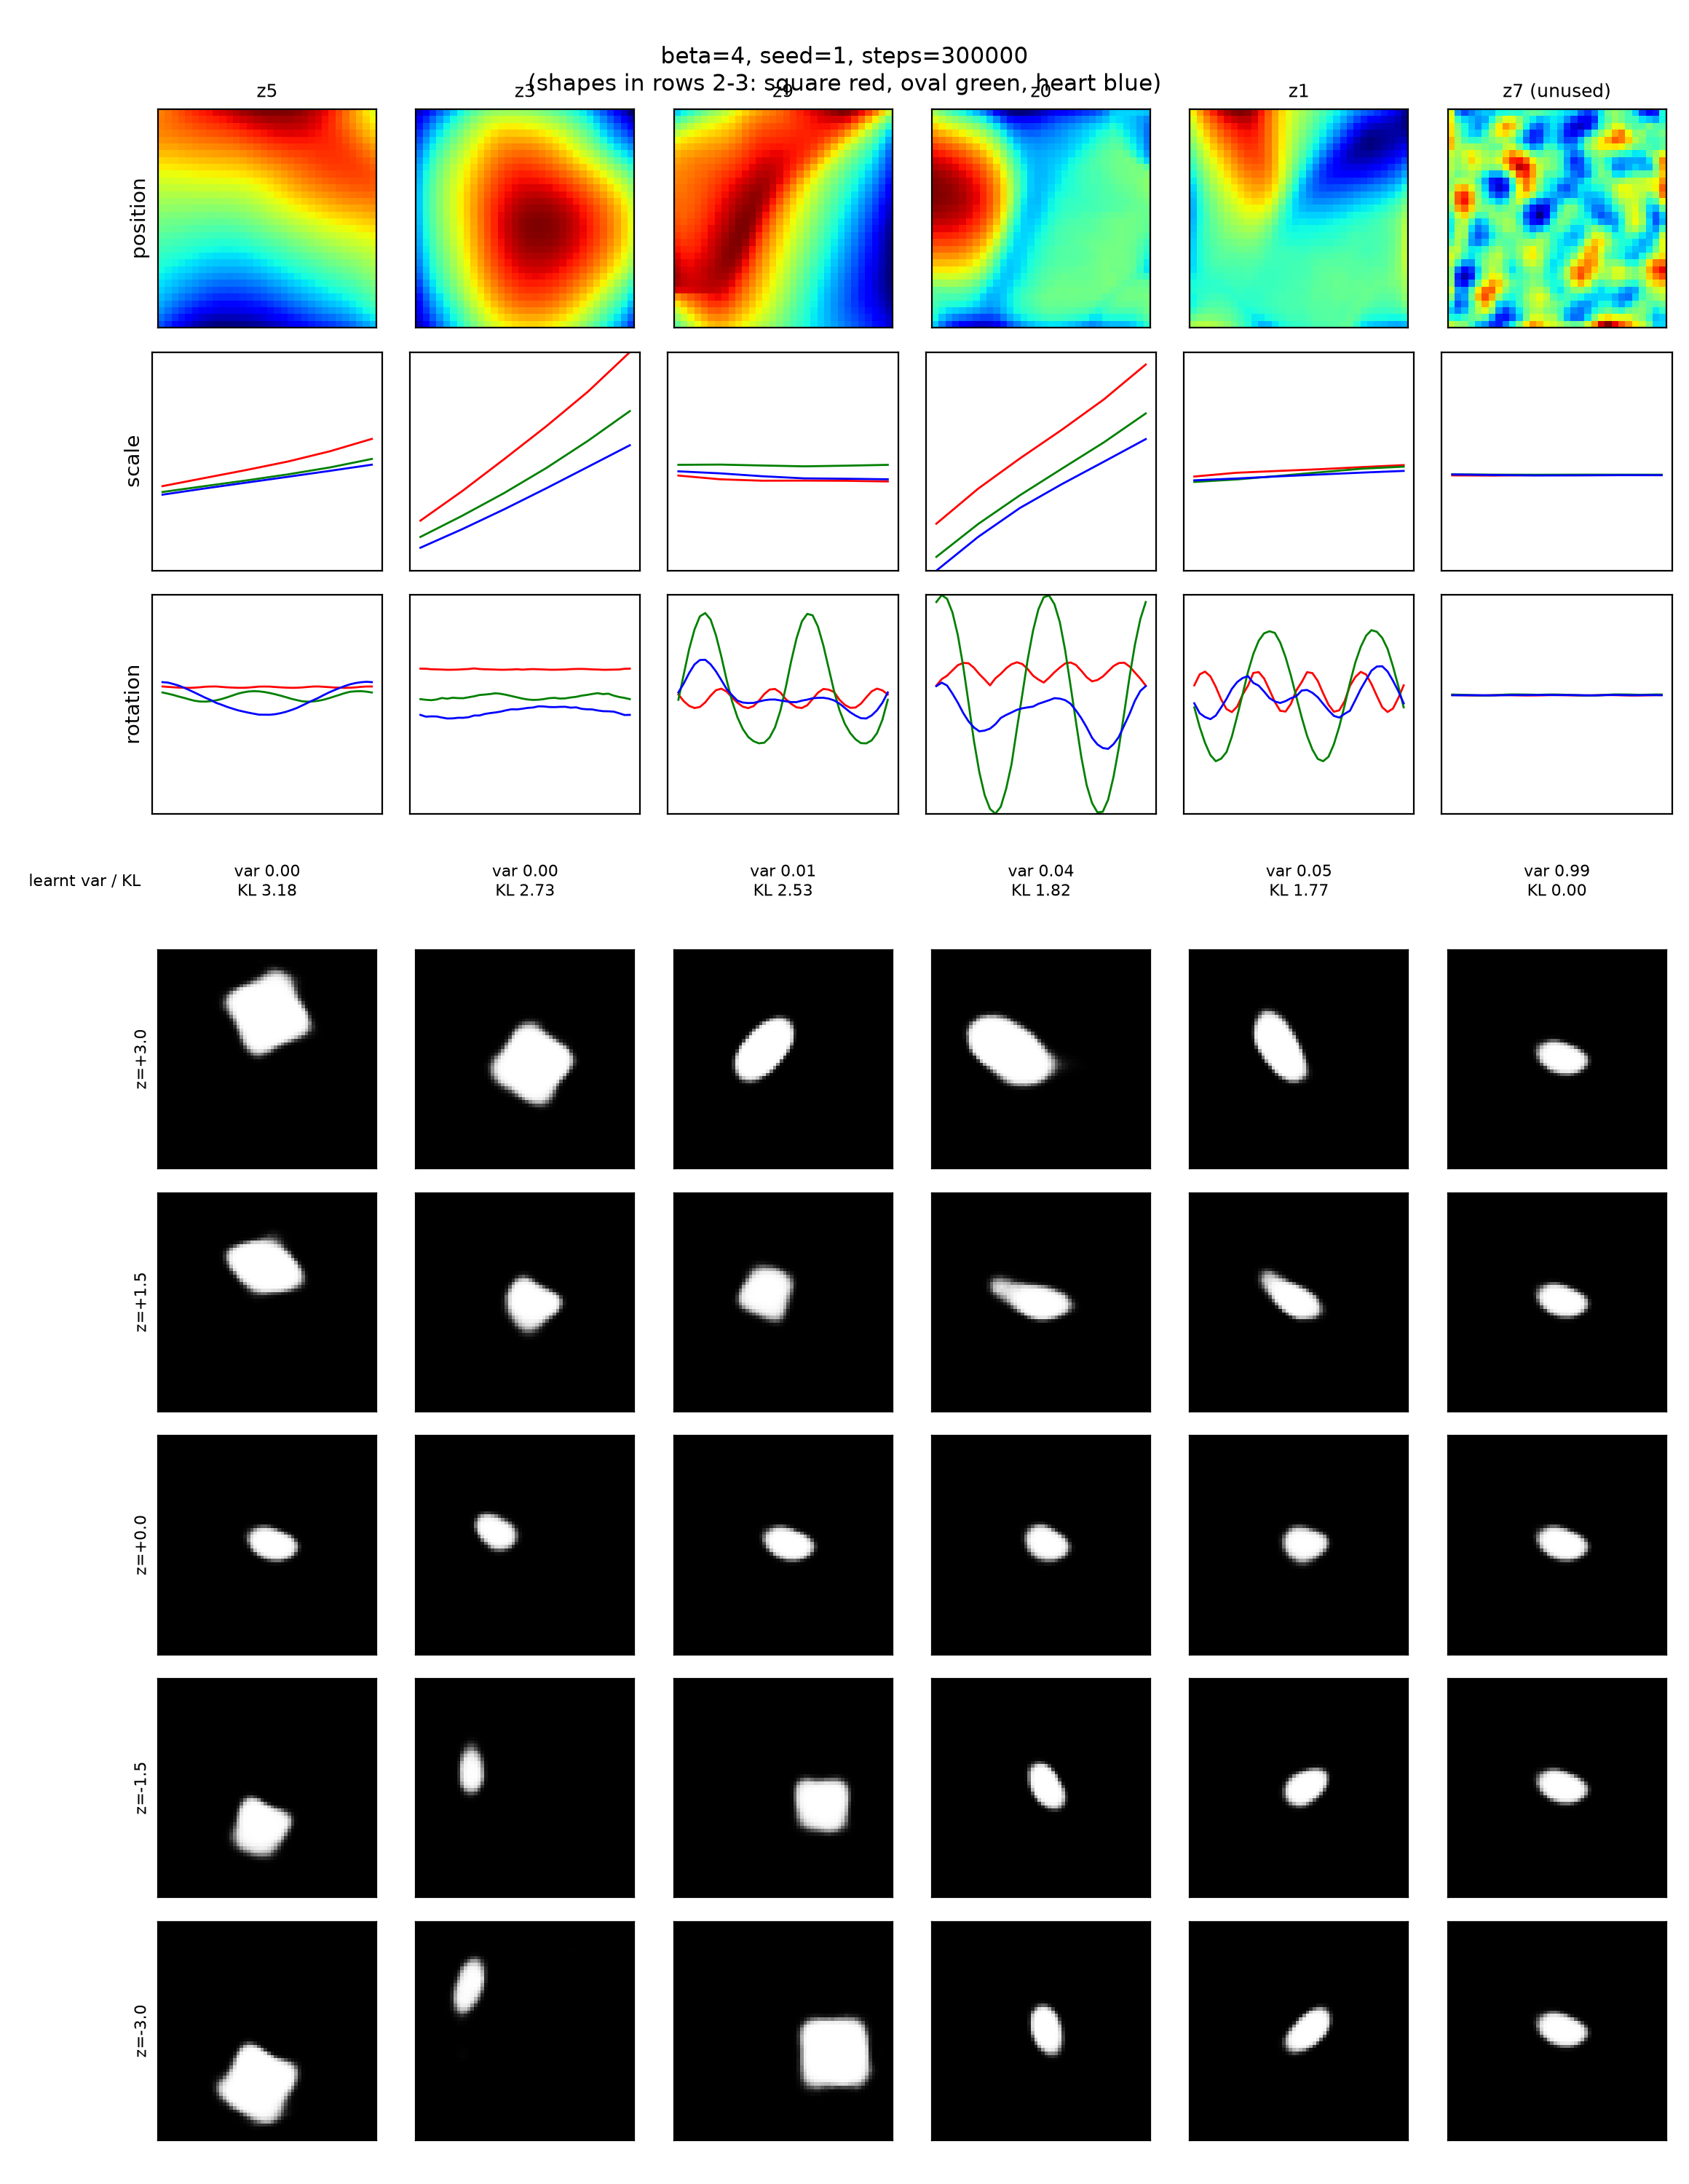

beta4_seed2


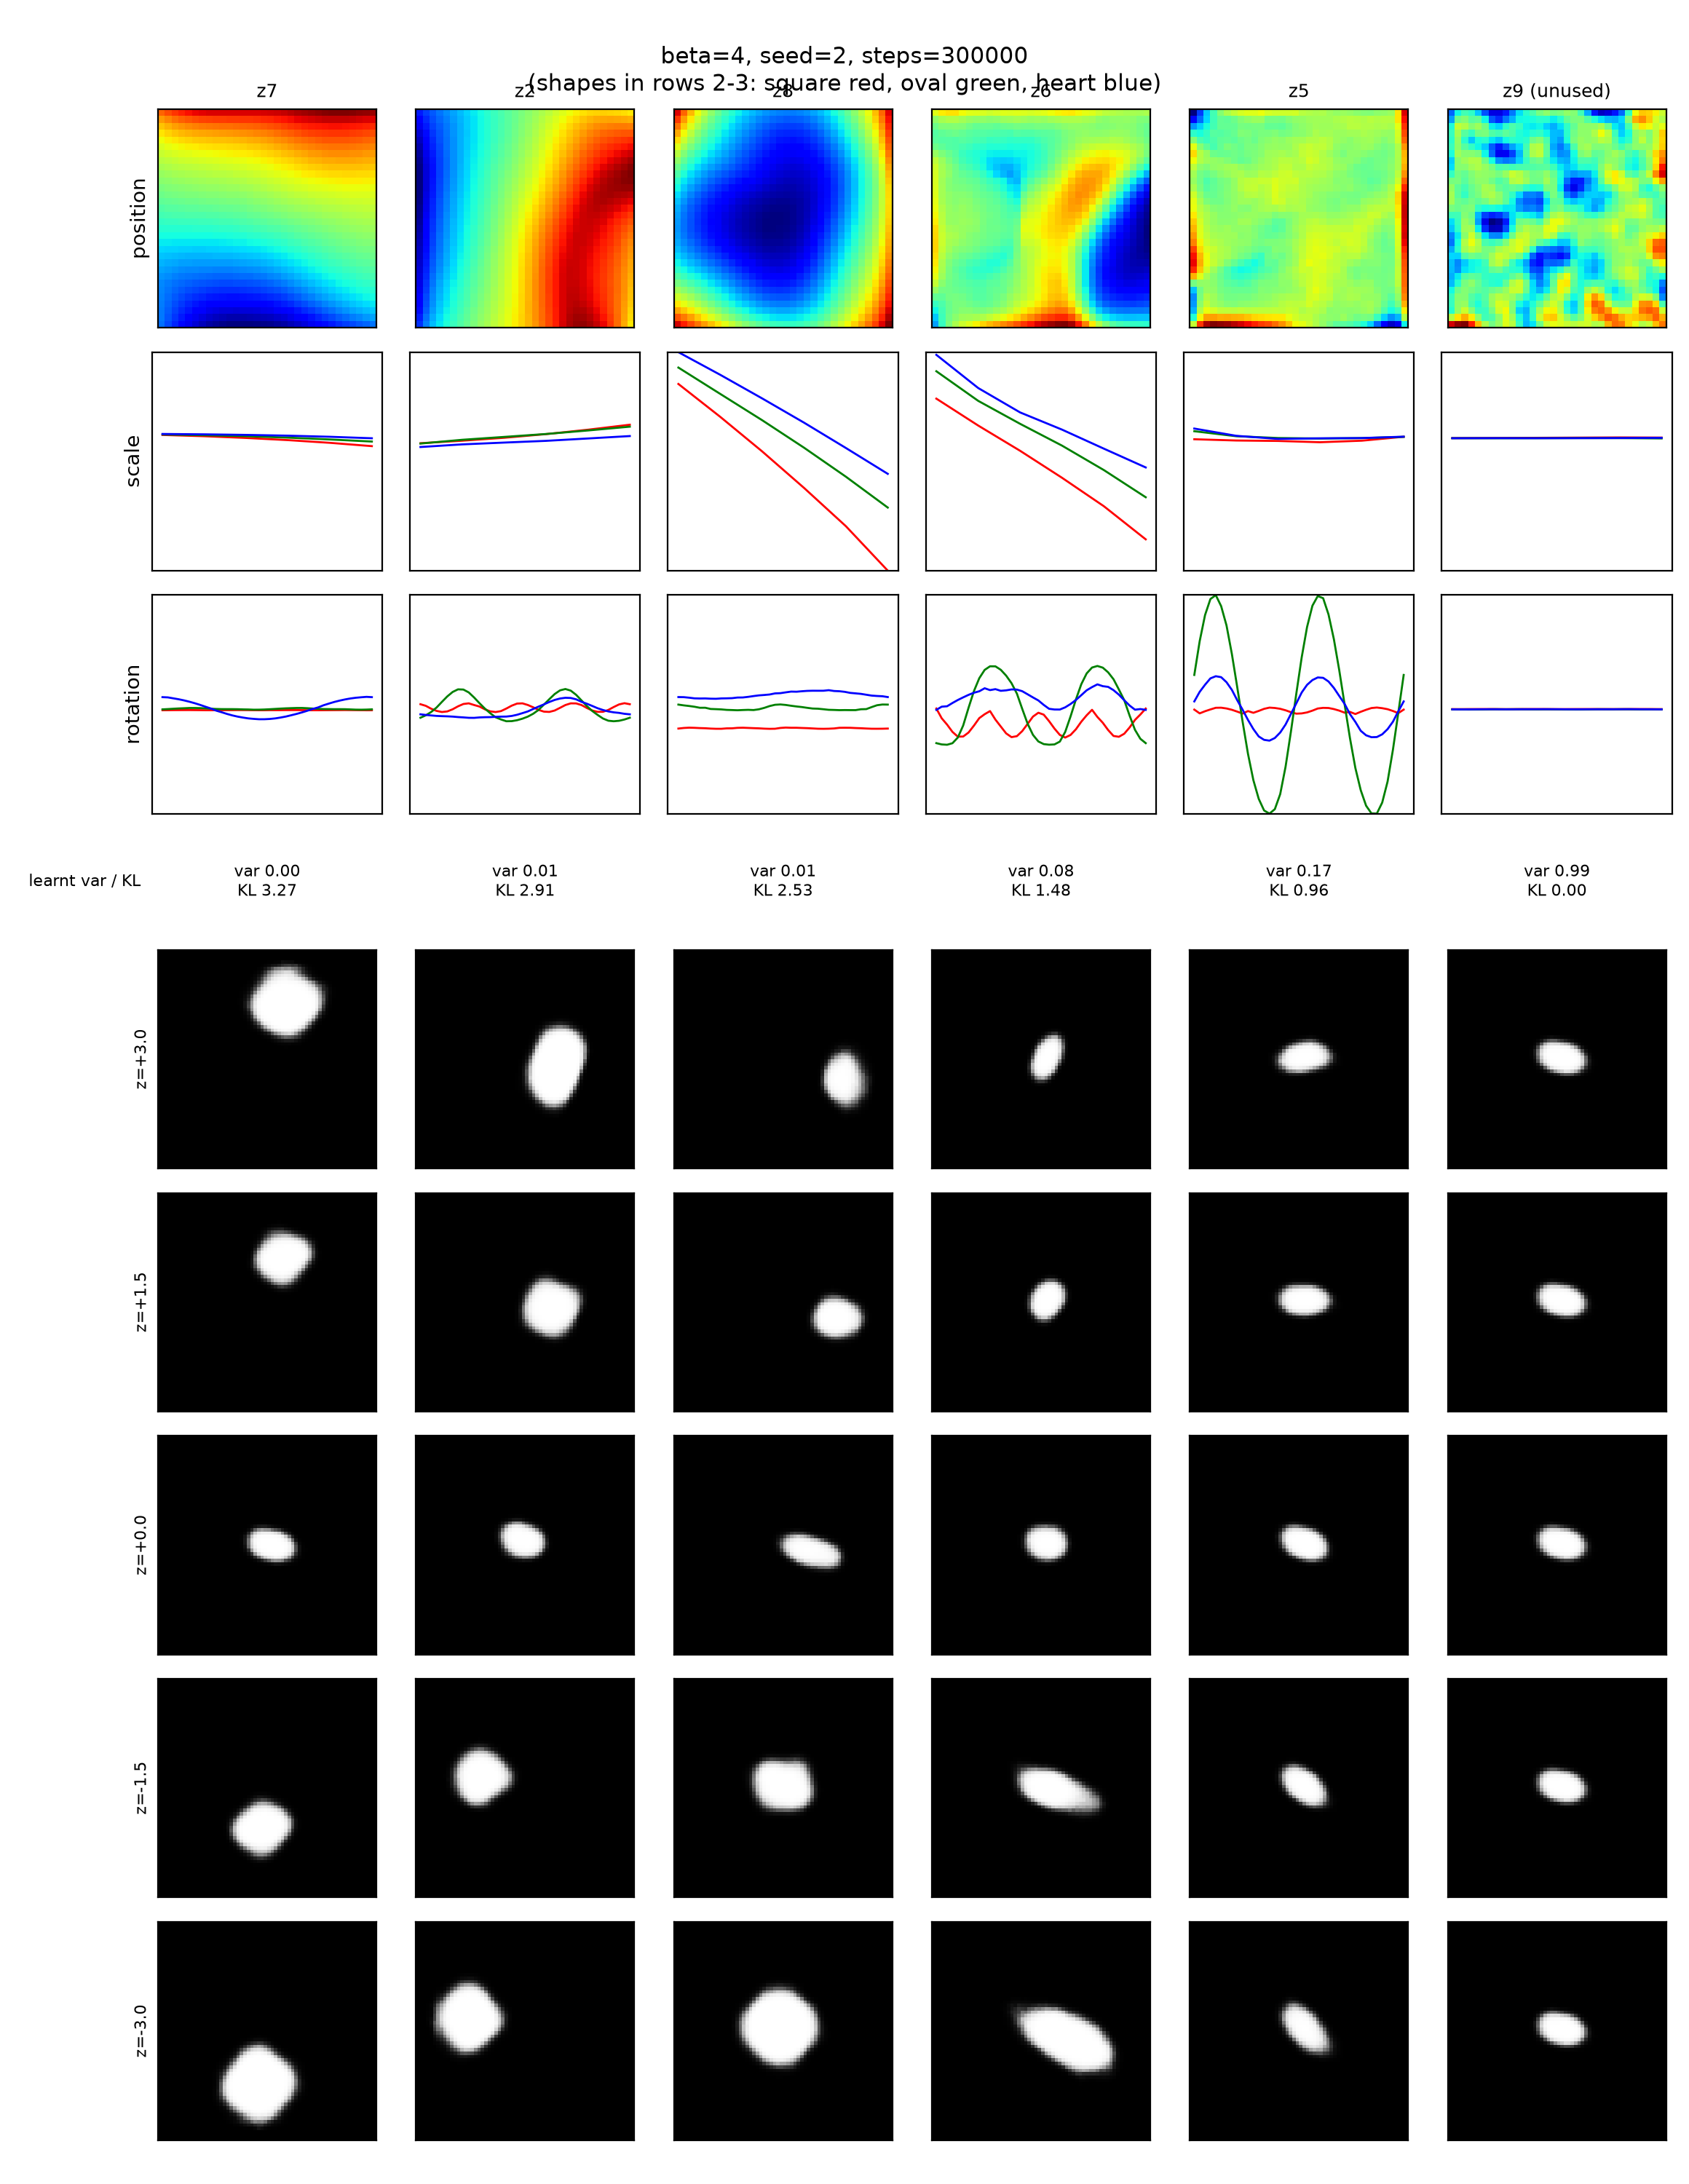

beta1_seed0


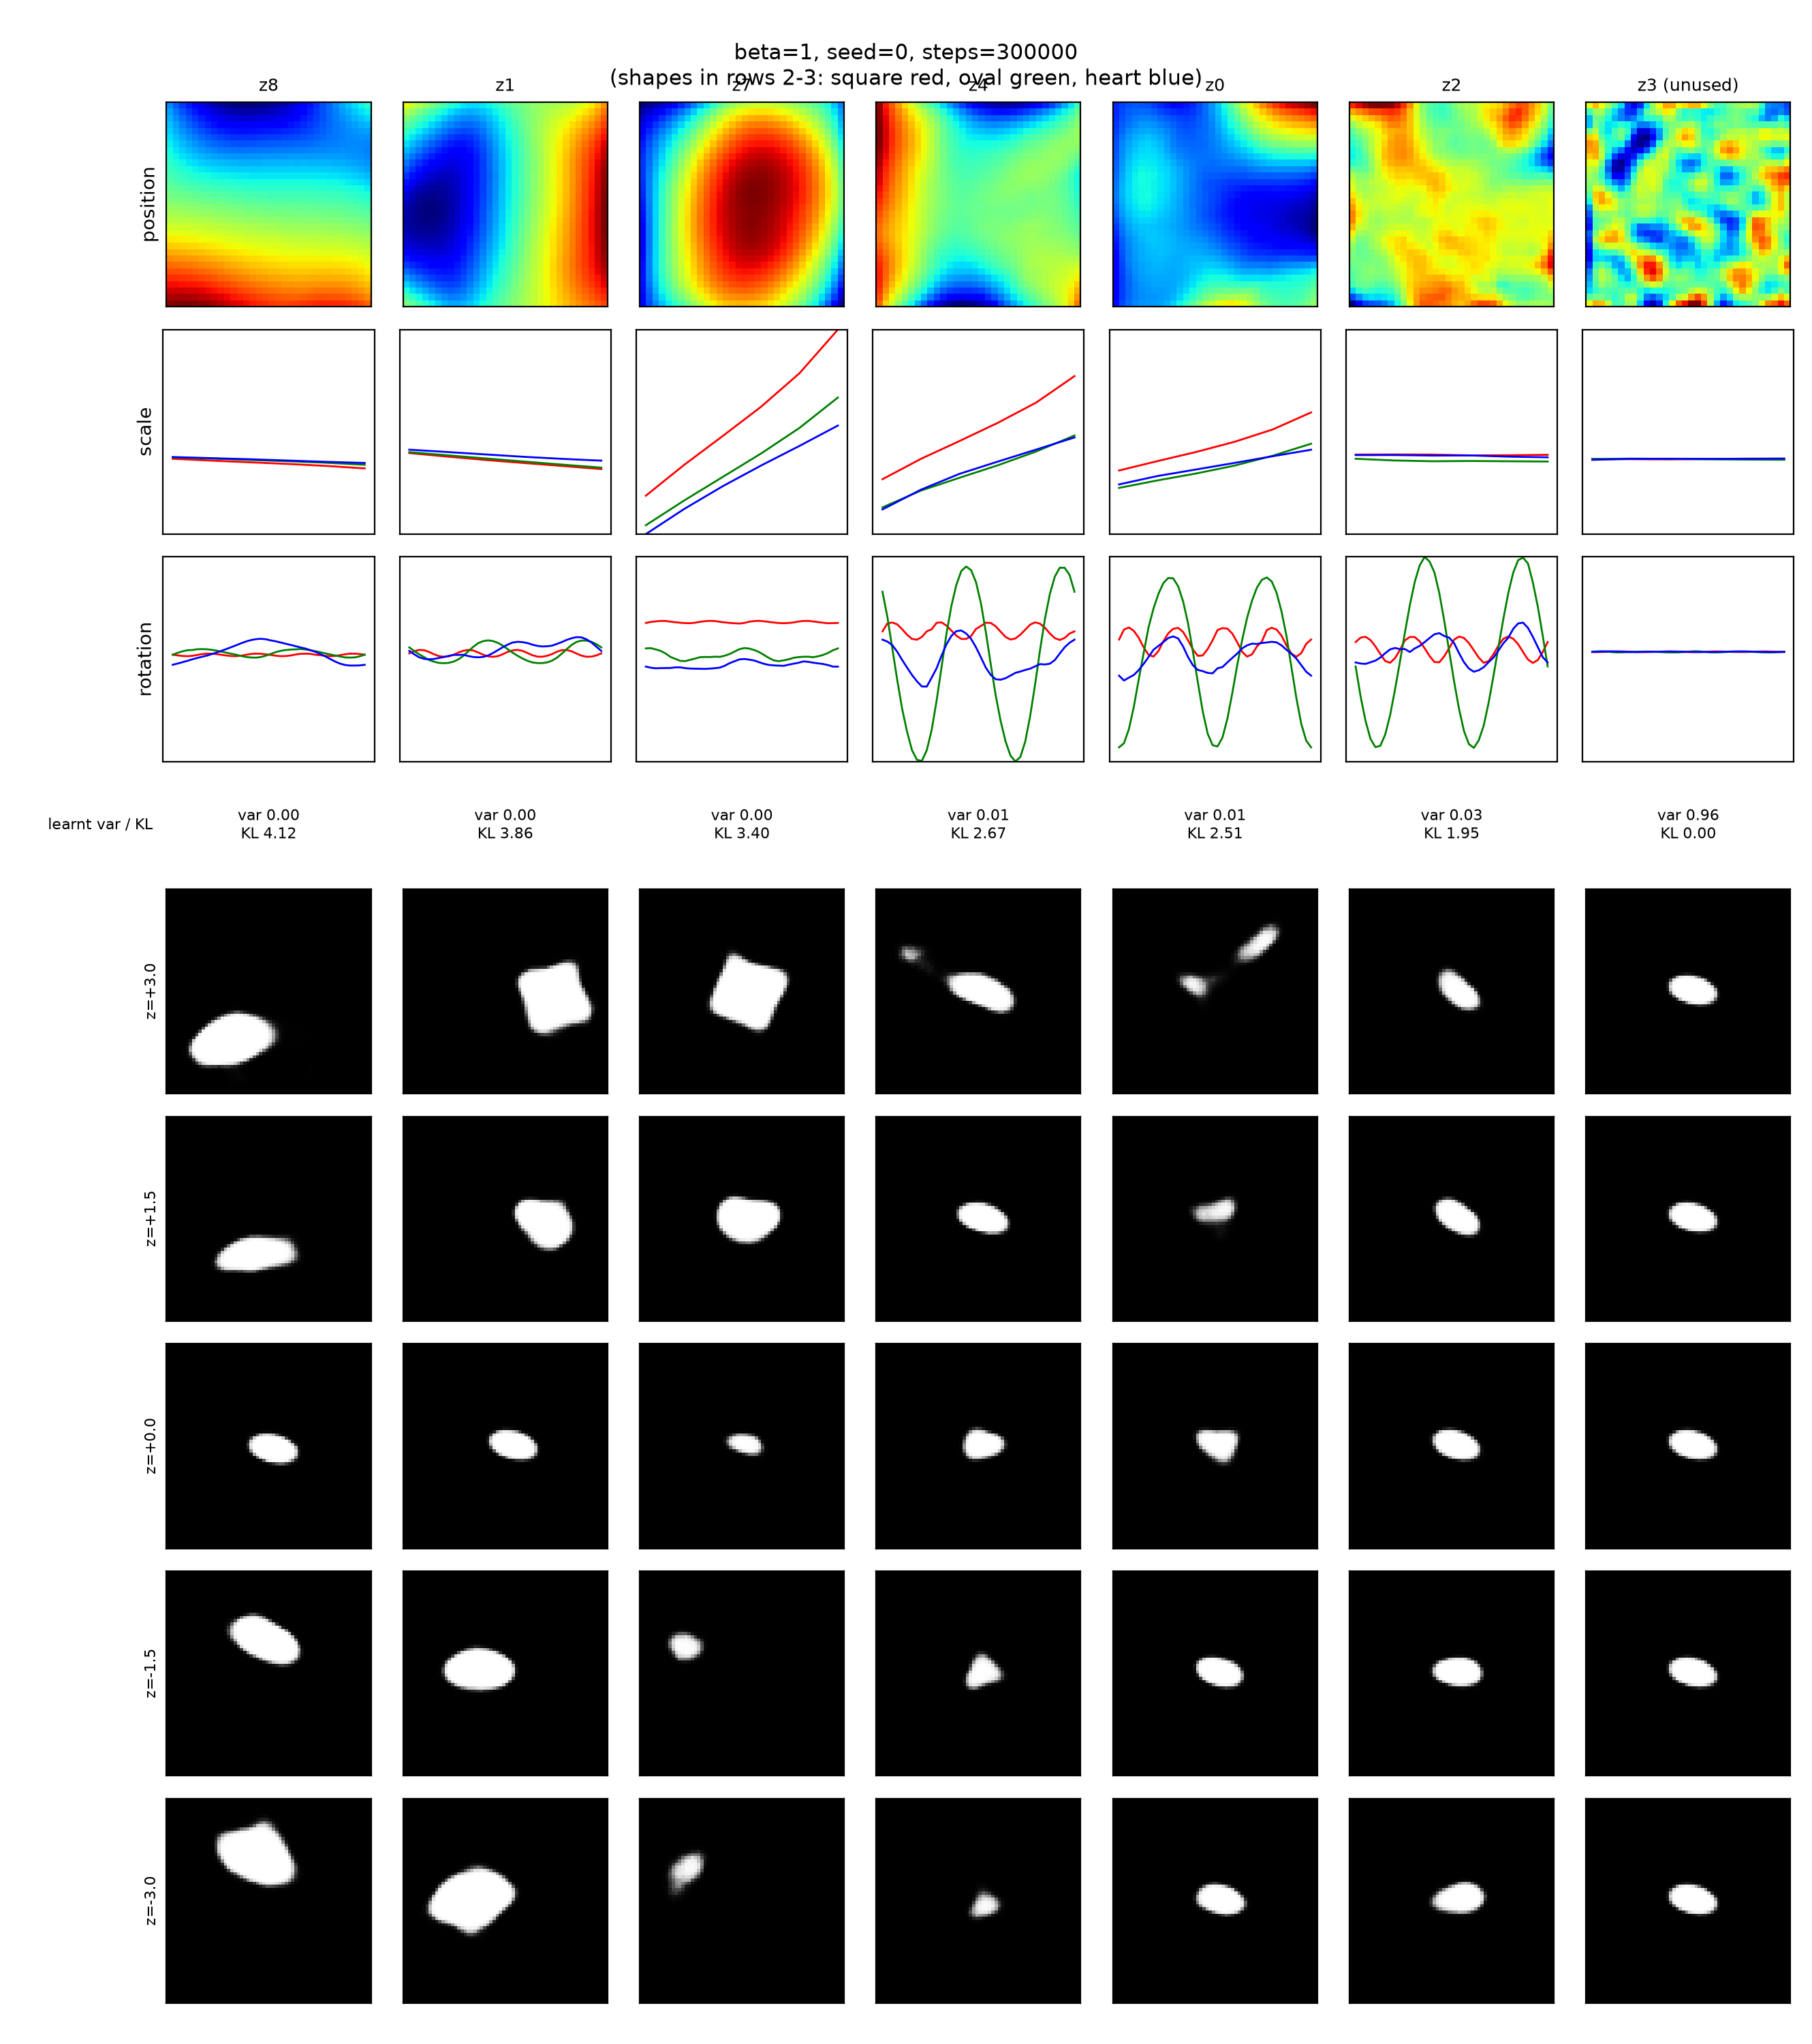

beta1_seed1


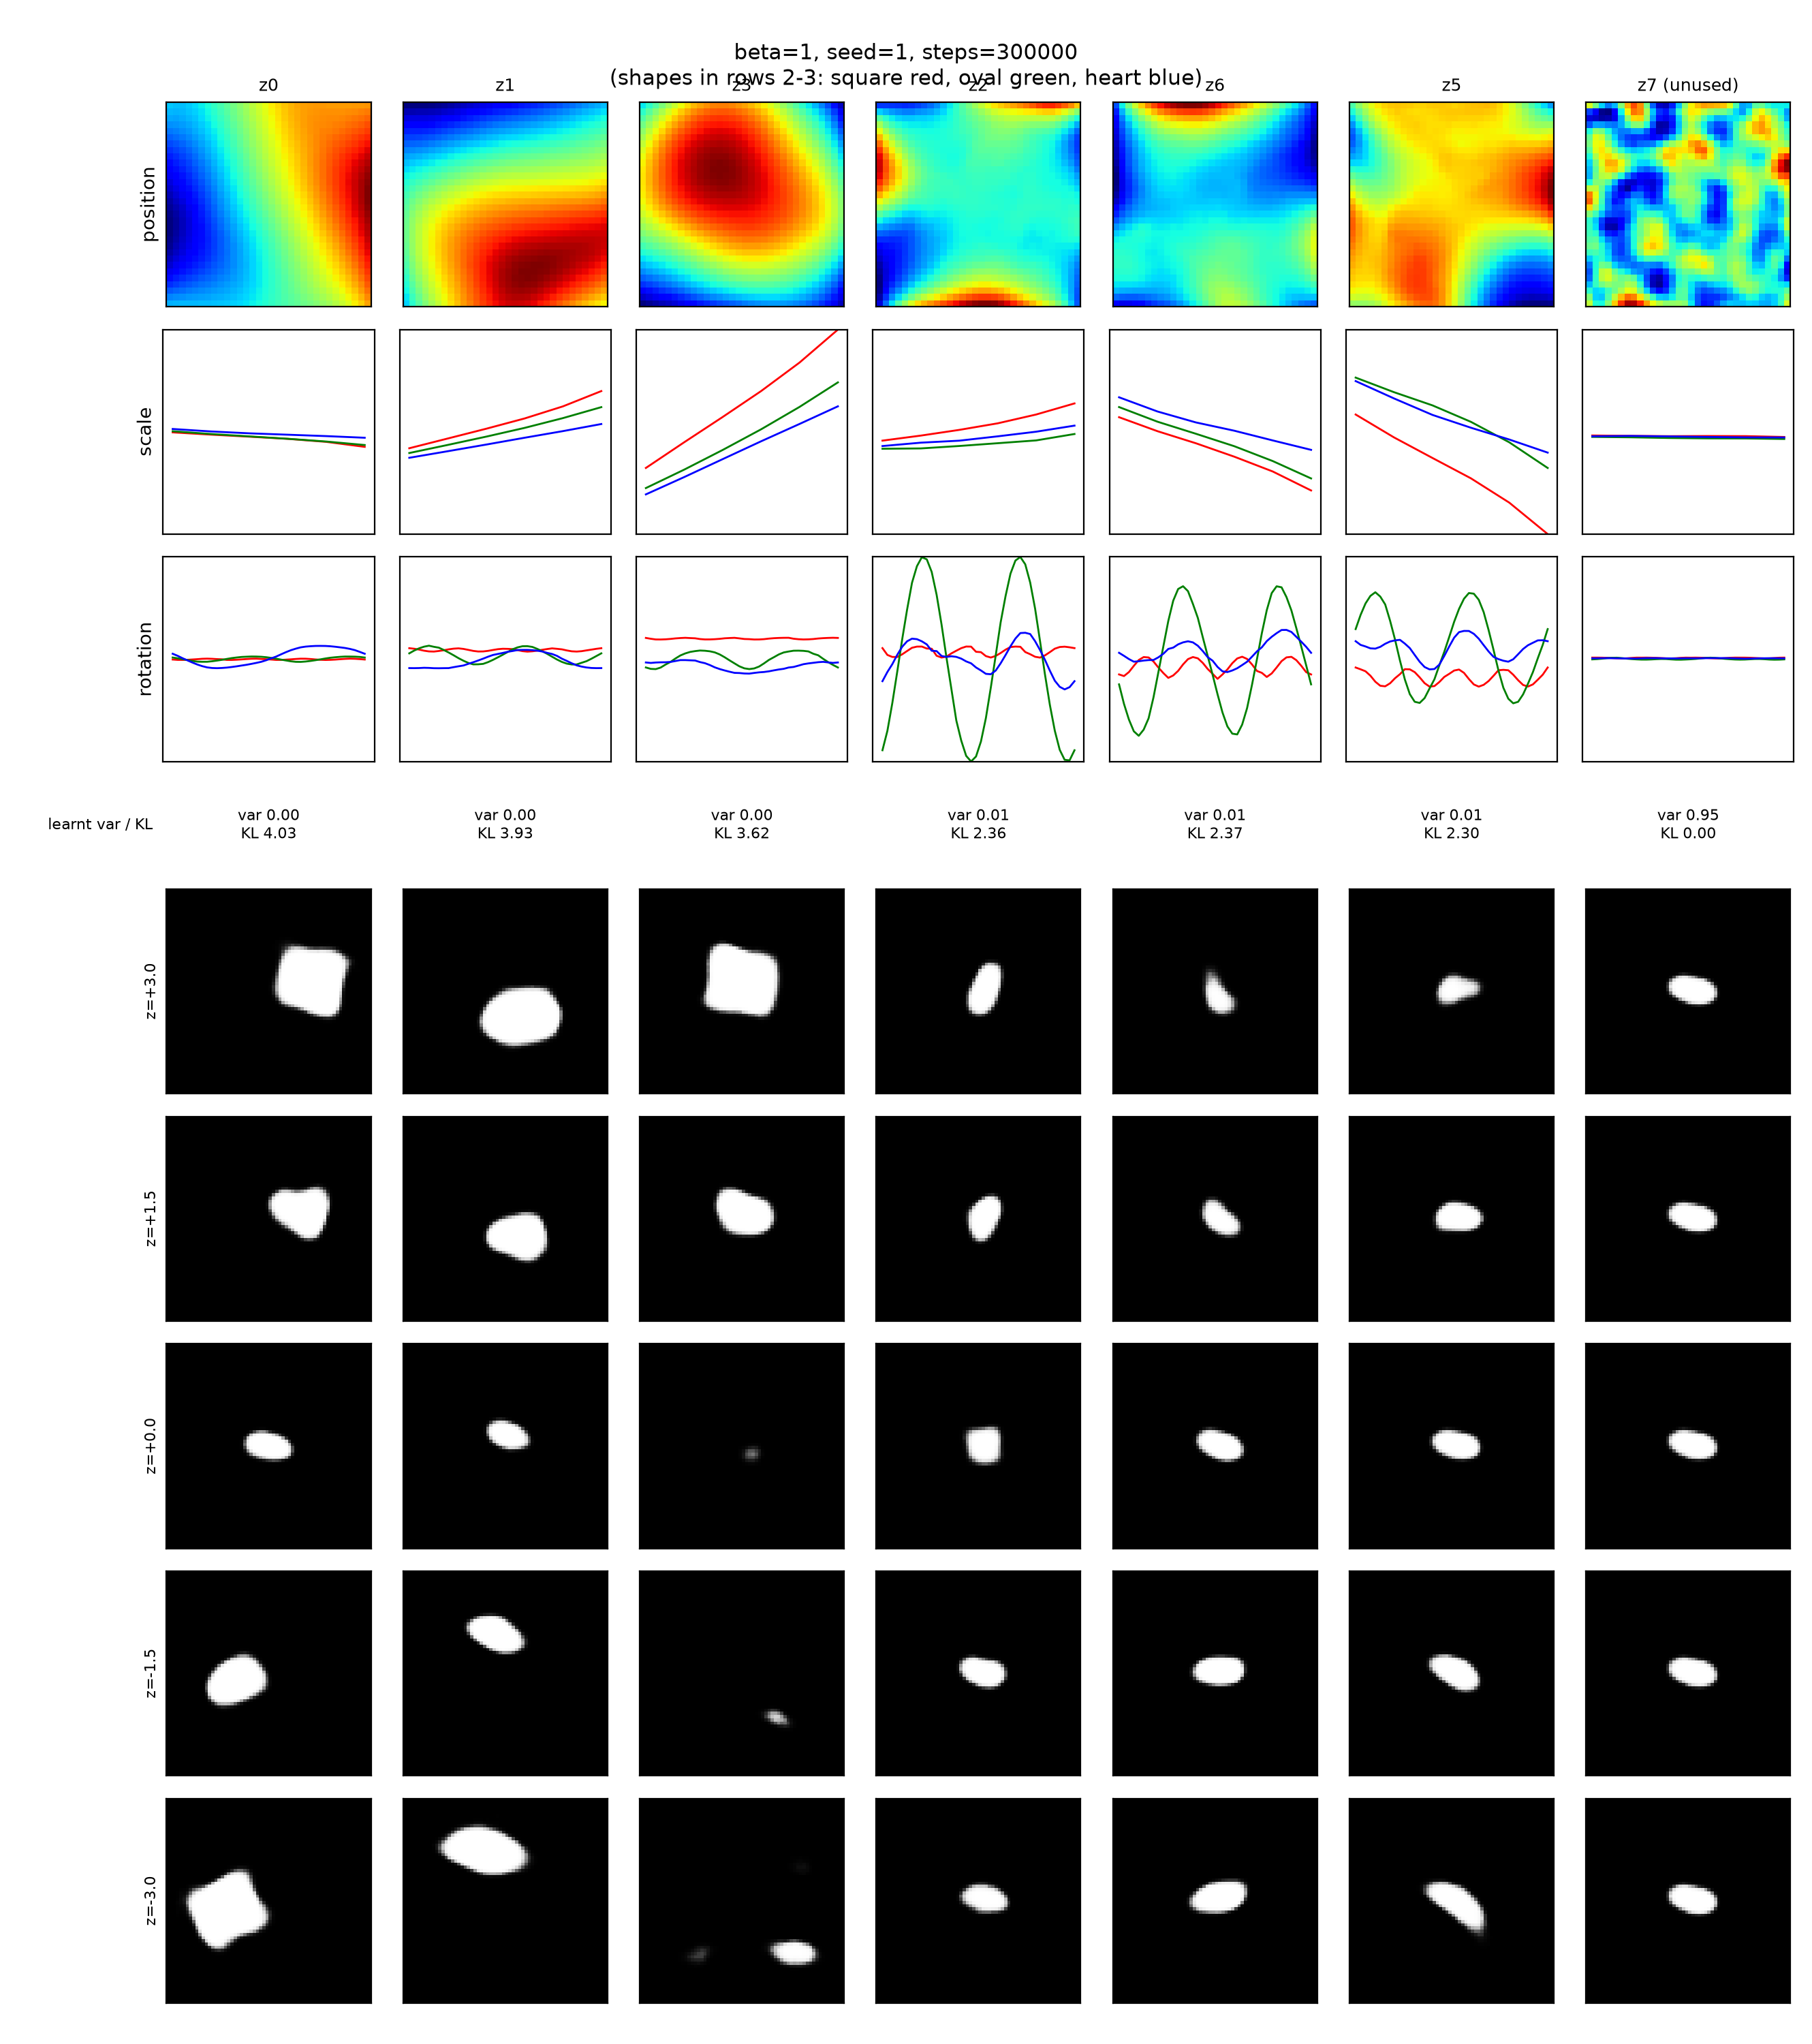

beta1_seed2


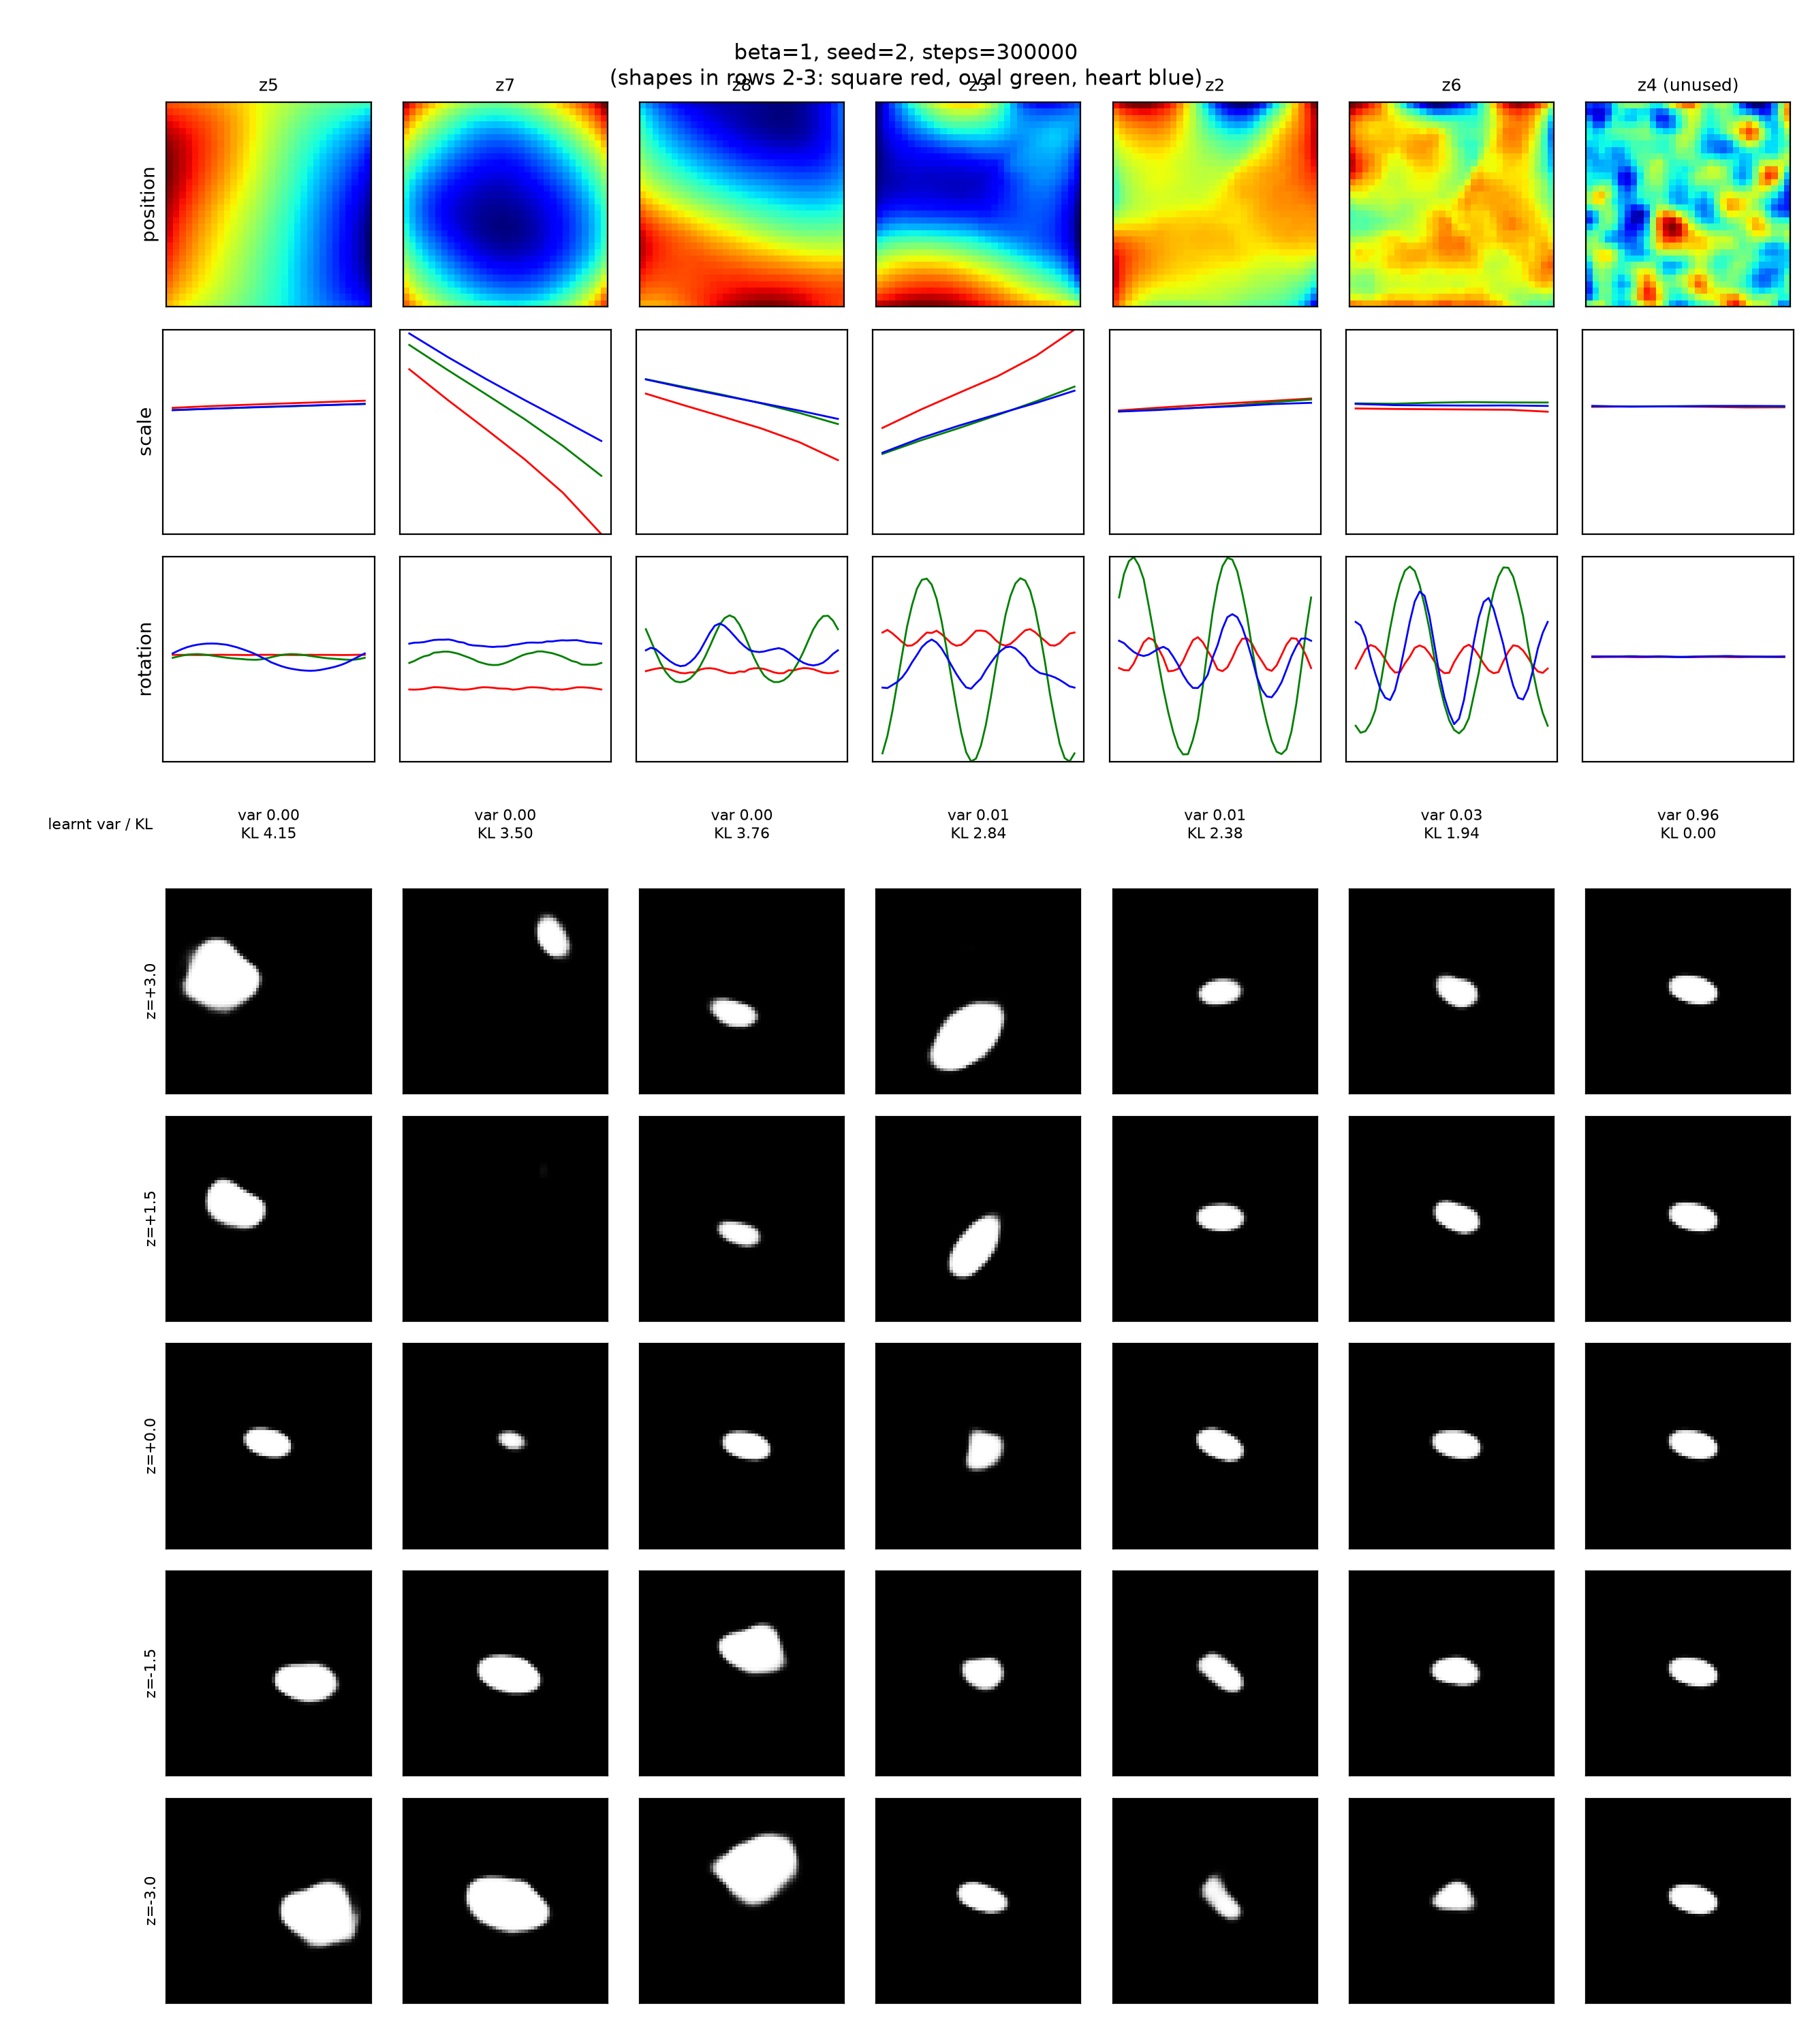

In [5]:
for beta in (4, 1):
    for f in sorted((HERE / "phase1_runs").glob(f"beta{beta}_seed*/fig7.png")):
        print(f.parent.name)
        display(Image(str(f)))